# Resultados do modelo

Avaliação no período de teste (junho a agosto de 2026, canais do Brasil), com o modelo treinado
até fevereiro e validado de março a maio. O alvo é `log((curtidas + 1) / (mediana + 1))`, o
desempenho do Short em relação aos Shorts estabilizados do próprio canal.

O notebook treina dois modelos com a mesma configuração dos experimentos registrados no MLflow:
o de metadados e texto (todos os Shorts) e o completo, com os blocos multimodais (sinais do vídeo
e do áudio, embeddings e rubrica do extrator). As comparações entre blocos usam o mesmo
subconjunto do teste em que todos os blocos existem.

In [1]:
import warnings

# Aviso do tqdm (sem barra de progresso no notebook), que imprimiria caminhos locais.
warnings.filterwarnings("ignore", message="IProgress not found")

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from creative_predictor import config
from creative_predictor.agent import faithfulness as ft
from creative_predictor.features.history import STALE_HISTORY_DAYS, history_risk
from creative_predictor.model import dataset as ds
from creative_predictor.model import multimodal as mm
from creative_predictor.model import train as tr
from creative_predictor.model.metrics import (
    band_edges,
    conformal_margin,
    evaluate,
    to_bands,
)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

table, blocks, _ = mm.build()
rows = ds.modeling_rows(table)
split = tr.make_split(rows, ("br", "global"))
edges = band_edges(split.train["target"])
risk = history_risk(table)  # histórico desatualizado ou canal em queda
meta = blocks["metadados"]
full = [f for block in blocks.values() for f in block]
models = {
    "metadados": tr.fit_lgbm(split.train, split.valid, meta, mm.OBJECTIVE),
    "completo": tr.fit_lgbm(split.train, split.valid, full, mm.OBJECTIVE),
}
test = split.test.copy()
test["pred_metadados"] = models["metadados"].predict(test[meta])
test["pred_completo"] = models["completo"].predict(test[full])
markers = ["brightness_mean", "vlm_forca_hook_0a10"] + [
    f"{k}_pc0" for k in ("frames", "audio", "transcript") if f"{k}_pc0" in test
]
test["completo_disponivel"] = (
    test[[m for m in markers if m in test]].notna().all(axis=1)
)
print(
    f"Teste: {len(test):,} Shorts; com todos os blocos: {test['completo_disponivel'].sum():,}"
)
print({b: len(f) for b, f in blocks.items()})

Teste: 2,821 Shorts; com todos os blocos: 899
{'metadados': 50, 'sinais': 26, 'embeddings': 48, 'extrator': 24}


## 1. Ganho por bloco

                          experimento     n  mae_log  spearman_within_channel  pairwise_accuracy  band_f1
               baseline_mediana_canal 899.0    0.727                      NaN              0.500    0.169
                       lgbm_metadados 899.0    0.683                    0.315              0.622    0.265
                          lgbm_sinais 899.0    0.686                    0.350              0.629    0.237
                      lgbm_embeddings 899.0    0.673                    0.371              0.644    0.275
                        lgbm_extrator 899.0    0.672                    0.392              0.648    0.269
lgbm_extrator_sem_rubrica_na_previsao 899.0    0.680                    0.358              0.646    0.259


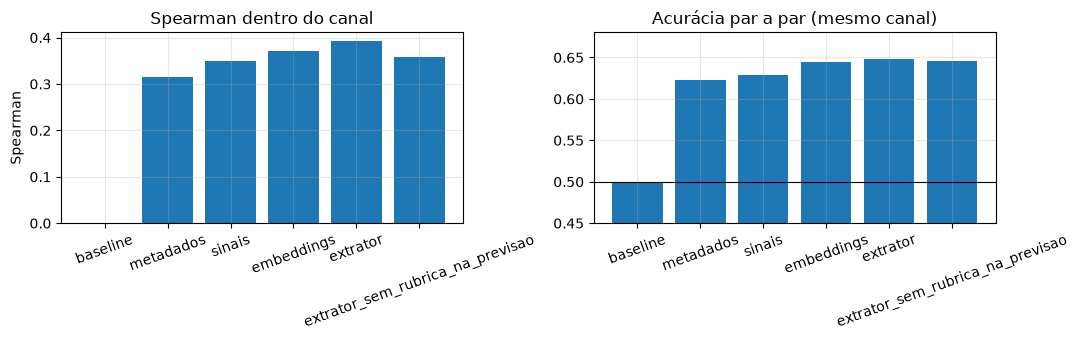

In [3]:
results = pd.read_csv(config.ROOT_DIR / "reports" / "multimodal_results.csv")
cols = [
    "experimento",
    "n",
    "mae_log",
    "spearman_within_channel",
    "pairwise_accuracy",
    "band_f1",
]
print(results[cols].round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
names = (
    results["experimento"]
    .str.replace("lgbm_", "")
    .str.replace("baseline_mediana_canal", "baseline")
)
axes[0].bar(names, results["spearman_within_channel"].fillna(0))
axes[0].set(title="Spearman dentro do canal", ylabel="Spearman")
axes[1].bar(names, results["pairwise_accuracy"])
axes[1].axhline(0.5, color="black", linewidth=0.8)
axes[1].set(title="Acurácia par a par (mesmo canal)", ylim=(0.45, None))
for ax in axes:
    ax.tick_params(axis="x", labelrotation=20)
plt.tight_layout()

## 2. Intervalo de 80% calibrado

In [4]:
low_m, high_m = (
    tr.fit_lgbm(split.train, split.valid, full, "quantile", alpha=a) for a in (0.1, 0.9)
)


def interval(frame):
    lo, hi = low_m.predict(frame[full]), high_m.predict(frame[full])
    return np.minimum(lo, hi), np.maximum(lo, hi)


v_lo, v_hi = interval(split.valid)
margin = conformal_margin(split.valid["target"], v_lo, v_hi, coverage=0.8)
# Folga própria para os Shorts de risco, calibrada só neles na validação.
v_risk = risk.reindex(split.valid.index).to_numpy(bool)
t_risk = risk.reindex(test.index).to_numpy(bool)
risk_margin = conformal_margin(
    split.valid["target"][v_risk], v_lo[v_risk], v_hi[v_risk], coverage=0.8
)
lo, hi = interval(test)
y = test["target"].to_numpy()


def cover(low, high, mask=slice(None)):
    return float(((y >= low) & (y <= high))[mask].mean())


single = (lo - margin, hi + margin)
m = np.where(t_risk, max(risk_margin, margin), margin)
test["low"], test["high"] = lo - m, hi + m
print(f"Folga geral: {margin:.3f}; folga dos Shorts de risco: {risk_margin:.3f}")
print(f"Cobertura no teste: quantis puros {cover(lo, hi):.1%}")
print(
    f"  com a folga geral: {cover(*single):.1%} (risco: {cover(*single, t_risk):.1%})"
)
print(
    f"  com a folga por grupo: {cover(lo - m, hi + m):.1%} "
    f"(risco: {cover(lo - m, hi + m, t_risk):.1%}; {t_risk.sum()} Shorts)"
)
inside = (test["target"] >= test["low"]) & (test["target"] <= test["high"])
print(test.assign(dentro=inside).groupby("sector")["dentro"].mean().round(3))

Folga geral: 0.070; folga dos Shorts de risco: 0.192
Cobertura no teste: quantis puros 75.8%
  com a folga geral: 78.9% (risco: 71.7%)
  com a folga por grupo: 79.7% (risco: 78.0%; 346 Shorts)
sector
automotivo    0.769
beleza        0.821
moda          0.801
Name: dentro, dtype: float64


## 3. Sinal de baixa confiança

In [5]:
width = test["high"] - test["low"]
v_width = (v_hi - v_lo) + 2 * margin
wide = np.quantile(v_width, 0.8)
test["flag_largo"] = width > wide
test["flag_desatualizado"] = test["history_age_days"] > STALE_HISTORY_DAYS
test["flag_risco"] = t_risk
# O motivo "menos de 10 Shorts estabilizados" só aparece na previsão de canais
# fora da base: na tabela de modelagem todo Short já tem 10 ou mais.
test["baixa_confianca"] = test["flag_largo"] | test["flag_risco"]
test["erro"] = (test["target"] - test["pred_completo"]).abs()
summary = test.groupby("baixa_confianca").agg(
    shorts=("erro", "size"), mae_log=("erro", "mean"), mediana_erro=("erro", "median")
)
print(summary.round(3))
print(f"Marcados: {test['baixa_confianca'].mean():.1%} do teste")
by_reason = {
    name: test.loc[test[flag], "erro"].agg(["size", "mean"]).round(3).tolist()
    for name, flag in [
        ("intervalo largo", "flag_largo"),
        (f"histórico desatualizado (> {STALE_HISTORY_DAYS} d)", "flag_desatualizado"),
        ("desatualizado ou canal em queda", "flag_risco"),
    ]
}
print("Por motivo [Shorts, MAE]:", by_reason)

                 shorts  mae_log  mediana_erro
baixa_confianca                               
False              1981    0.554         0.423
True                840    0.886         0.691
Marcados: 29.8% do teste
Por motivo [Shorts, MAE]: {'intervalo largo': [673.0, 0.94], 'histórico desatualizado (> 180 d)': [68.0, 1.232], 'desatualizado ou canal em queda': [346.0, 0.871]}


Se o sinal funciona, os Shorts marcados como de baixa confiança erram mais que os demais. Os
motivos ligados ao histórico do canal (histórico desatualizado ou canal em queda) foram
calibrados na validação (`model.confidence`); nesses Shorts o intervalo usa uma folga própria.
Para canais fora da base de treino (como os de demonstração), o sinal também acende: nesse caso
o modelo usa padrões gerais do setor, sem ter visto o canal.

## 4. O que mais pesa nas previsões (SHAP)

Contribuição média absoluta por bloco (log):
metadados     0.824
embeddings    0.105
sinais        0.047
extrator      0.025
dtype: float64


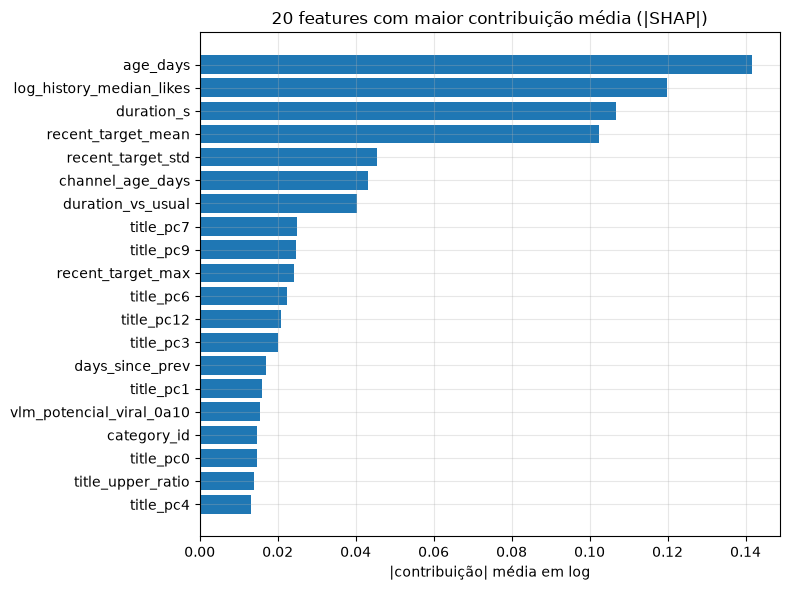

In [6]:
contrib = models["completo"].predict(test[full], pred_contrib=True)[:, :-1]
importance = pd.Series(np.abs(contrib).mean(axis=0), index=full).sort_values(
    ascending=False
)


def block_of(feature):
    return next(b for b, fs in blocks.items() if feature in fs)


by_block = (
    importance.groupby(importance.index.map(block_of))
    .sum()
    .sort_values(ascending=False)
)
print("Contribuição média absoluta por bloco (log):")
print((by_block / by_block.sum()).round(3))
top = importance.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values)
ax.set(
    title="20 features com maior contribuição média (|SHAP|)",
    xlabel="|contribuição| média em log",
)
plt.tight_layout()

## 5. Análise de erros

In [7]:
channels = pd.read_parquet(config.PROCESSED_DIR / "channels.parquet").set_index(
    "channel_id"
)
test["low_engagement"] = test["channel_id"].map(channels["low_engagement"])


def by(frame, column, pred="pred_completo"):
    out = {}
    for value, part in frame.groupby(column, observed=True):
        r = evaluate(part, part[pred].to_numpy(), edges)
        out[value] = {
            k: r[k]
            for k in ("n", "mae_log", "spearman_within_channel", "pairwise_accuracy")
        }
    return pd.DataFrame(out).T.round(3)


print("Por setor:\n", by(test, "sector"))
print("\nPor tipo de canal:\n", by(test, "kind"))
print("\nPor engajamento do canal:\n", by(test, "low_engagement"))

Por setor:
                 n  mae_log  spearman_within_channel  pairwise_accuracy
automotivo  956.0    0.734                    0.358              0.610
beleza      915.0    0.677                    0.361              0.592
moda        950.0    0.548                    0.407              0.657



Por tipo de canal:
               n  mae_log  spearman_within_channel  pairwise_accuracy
criador  2130.0    0.614                    0.376              0.644
marca     691.0    0.774                    0.372              0.559

Por engajamento do canal:
             n  mae_log  spearman_within_channel  pairwise_accuracy
False  2631.0    0.658                    0.384              0.624
True    190.0    0.580                    0.223              0.545


In [8]:
size = pd.qcut(
    test["log_history_median_likes"],
    4,
    labels=["pequeno", "médio", "grande", "muito grande"],
)
print(
    "Por tamanho do canal (quartis da mediana de curtidas):\n",
    by(test.assign(porte=size), "porte"),
)
names = channels["name"]
worst = test.assign(
    canal=test["channel_id"].map(names),
    real=np.exp(test["target"]).round(2),
    previsto=np.exp(test["pred_completo"]).round(2),
).nlargest(8, "erro")
print("\nMaiores erros (em vezes a mediana do canal):")
print(worst[["canal", "title", "real", "previsto"]].to_string(index=False))

Por tamanho do canal (quartis da mediana de curtidas):
                   n  mae_log  spearman_within_channel  pairwise_accuracy
pequeno       709.0    0.617                    0.323              0.613
médio         712.0    0.648                    0.377              0.576
grande        696.0    0.671                    0.322              0.633
muito grande  704.0    0.677                    0.382              0.636

Maiores erros (em vezes a mediana do canal):
                  canal                                                                            title   real  previsto
            Dove Brasil                   Transforme o banho no primeiro passo da sua rotina de skincare 127.05      0.56
         Renault Brasil                                          a Renault está sempre no centro da ação 171.05      0.85
         Renault Brasil                                                                 #Renault #Boreal 273.79      1.41
Adriana Oliveira (loja)                      

## 6. Faixas

In [9]:
real = pd.Categorical(
    to_bands(test["target"], edges), ["abaixo", "na_media", "acima", "viral"]
)
pred = pd.Categorical(
    to_bands(test["pred_completo"], edges), ["abaixo", "na_media", "acima", "viral"]
)
print(pd.crosstab(real, pred, rownames=["real"], colnames=["previsto"]))

previsto  abaixo  na_media  acima
real                             
abaixo       121       672      9
na_media      63      1363     43
acima         24       417     41
viral          8        57      3


O modelo raramente prevê as faixas extremas: a previsão tende ao centro, como acontece com
regressão sobre um alvo ruidoso. Por isso a decisão entre criativos usa a ordenação e o
desempenho relativo, e a faixa entra como resumo.

## 7. LLM sem modelo × modelo treinado

O LLM do agente (`gemma4:12b`) recebe o que uma pessoa de marketing teria antes de publicar
(frames, título, duração, transcrição, mediana e últimos Shorts do canal) e chuta as curtidas;
o chute vira o mesmo alvo do modelo. Mesmos Shorts do teste, mesmas métricas
(`model.llm_baseline`).

In [10]:
llm = pd.read_csv(config.ROOT_DIR / "reports" / "llm_baseline_results.csv")
cols = ["experimento", "n", "mae_log", "spearman_within_channel", "pairwise_accuracy"]
print(llm[cols].round(3).to_string(index=False))

              experimento     n  mae_log  spearman_within_channel  pairwise_accuracy
   baseline_mediana_canal 198.0    0.776                      NaN              0.500
llm_sem_modelo_gemma4:12b 198.0    1.127                    0.014              0.504
     lgbm_todos_os_blocos 198.0    0.701                    0.422              0.668


## 8. Fidelidade das explicações

Explicações escritas pelo LLM do agente para Shorts do teste, conferidas automaticamente
(`agent.faithfulness`): números citados que não estão nos dados recebidos, fatores citados e
coerência com o sinal de baixa confiança.

In [11]:
explanations = pd.read_csv(config.ROOT_DIR / "reports" / "explanation_faithfulness.csv")
for key, value in ft.summarize(explanations).items():
    print(f"{key}: {value:.3f}" if isinstance(value, float) else f"{key}: {value}")

explicacoes: 100
sem_numero_inventado: 1.000
numeros_sem_base_total: 0
numeros_citados_total: 516
citam_fator: 1.000
baixa_confianca_afirmada: 1.000
alta_confianca_contradita: 0.000
